# 02 · Modelo predictivo de devoluciones

**Predicción de devoluciones de inventario y ajuste de la demanda neta de equipos móviles**
Grupo 5 — Maestría en Inteligencia Artificial Aplicada, UDLA

Fases 3 y 4 de CRISP-ML(Q). Requiere haber ejecutado `01_limpieza_y_eda.ipynb`.

Se entrenan dos modelos que responden preguntas distintas:

- **Modelo agregado** — *¿cuántas unidades de una marca se devolverán el mes que viene?* Es
  regresión sobre volumen, que es lo que el capstone comprometió, y es lo que usa planificación.
- **Modelo por unidad** — *¿esta unidad recién despachada se va a devolver?* Sus probabilidades se
  suman por marca y mes para producir el mismo volumen, pero aprovechando 127 mil observaciones en
  lugar de 228.

In [1]:
import sys, warnings, types
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from xgboost import XGBRegressor, XGBClassifier

from src import modelo as M
from src.config import REPORTES, SEMILLA, UMBRAL_DIAS

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": .3, "font.size": 10})
np.random.seed(SEMILLA)
PROC = RAIZ / "data" / "processed"

panel = pd.read_parquet(PROC / "v2_panel_marca_mes.parquet")
ciclo = pd.read_parquet(PROC / "v2_ciclo_limpio.parquet")
print("panel marca×mes:", panel.shape, "| ciclo:", ciclo.shape)

panel marca×mes: (198, 7) | ciclo: (148913, 27)


## 1. Definición del problema

```
TAREA     : regresión sobre conteos no negativos
TARGET    : y[marca, mes] = unidades devueltas
            DEVOLUCIÓN := unidad despachada a un local que permanece
                          UMBRAL_DIAS o más sin venderse
GRANO     : marca × mes
HORIZONTE : h = 1 mes
VENTANA   : desde 2025-01 (el reporte de ventas de 2024 está incompleto)
FEATURES  : solo información disponible al cierre del mes t
USO       : demanda_neta[t+1] = pedido[t+1] − ŷ[t+1]
```

## 2. Elección del grano

El grano que pide el negocio es marca × mes. Antes de fijarlo conviene medir cuánta señal deja,
porque un panel con demasiadas celdas en cero no entrena.

In [2]:
granos = {}
for nom, arch in [("marca × mes", "v2_panel_marca_mes"),
                  ("marca × ciudad × mes", "v2_panel_marca_ciudad_mes"),
                  ("sku × mes", "v2_panel_sku_mes")]:
    p = pd.read_parquet(PROC / f"{arch}.parquet")
    granos[nom] = p
    print(f"{nom:24s} filas {len(p):>6,} | meses {p.mes.nunique():2d} | "
          f"densidad {(p.devueltas>0).mean():6.1%} | devoluciones {int(p.devueltas.sum()):,}")

marca × mes              filas    198 | meses 18 | densidad  61.6% | devoluciones 12,982
marca × ciudad × mes     filas  8,712 | meses 18 | densidad  14.6% | devoluciones 12,982
sku × mes                filas  5,454 | meses 18 | densidad  19.8% | devoluciones 12,982


**Decisión.** El modelo agregado se entrena en **marca × mes**, que es el nivel de la decisión de
negocio. El panel es pequeño pero denso, que es lo que importa para una serie de conteos.

El grano fino se reserva para el modelo por unidad de la sección 8, que no sufre el problema de la
agregación porque cada unidad es una observación.

## 3. Variables

Todas calculadas con información disponible **antes** del mes que se predice.

In [3]:
# Los dos primeros meses de la serie son calentamiento: las devoluciones que
# les tocarian corresponden a unidades despachadas antes de la ventana, que no
# estan en el panel. Se descartan para no meter dos ceros artificiales.
panel = panel[panel.mes >= panel.mes.min() + pd.DateOffset(months=2)]
p = panel.sort_values(["marca", "mes"]).reset_index(drop=True)
g = p.groupby("marca", observed=True)

for l in (1, 2, 3):
    p[f"dev_lag{l}"] = g["devueltas"].shift(l)
    p[f"desp_lag{l}"] = g["despachadas"].shift(l)
p["dev_mm3"] = g["devueltas"].shift(1).rolling(3, min_periods=1).mean().values
p["dev_mm6"] = g["devueltas"].shift(1).rolling(6, min_periods=1).mean().values
p["desp_mm3"] = g["despachadas"].shift(1).rolling(3, min_periods=1).mean().values
p["tasa_hist"] = (g["devueltas"].cumsum() - p["devueltas"]) / \
                 (g["despachadas"].cumsum() - p["despachadas"]).replace(0, np.nan)
p["tendencia"] = p["dev_lag1"] - p["dev_lag2"]

# Los despachos de hace UMBRAL_DIAS son los que pueden devolverse este mes:
# es la variable con sentido causal más directo del panel.
p["desp_rezago_umbral"] = g["despachadas"].shift(max(1, round(UMBRAL_DIAS / 30)))

p["mes_num"] = p.mes.dt.month
p["mes_sin"] = np.sin(2 * np.pi * p.mes_num / 12)
p["mes_cos"] = np.cos(2 * np.pi * p.mes_num / 12)

# Sin indice de tiempo ni ano como variables: XGBoost con objetivo Poisson usa
# enlace logaritmico, y al predecir un periodo posterior al entrenamiento
# extrapola exponencialmente. Es una fuente clasica de predicciones absurdas.
FEATURES = [c for c in p.columns
            if c not in {"devueltas", "mes", "valor_devuelto", "despachadas",
                         "valor_despachado", "tasa_devolucion", "mes_num"}]
print(f"{len(FEATURES)} variables:", FEATURES)

15 variables: ['marca', 'dev_lag1', 'desp_lag1', 'dev_lag2', 'desp_lag2', 'dev_lag3', 'desp_lag3', 'dev_mm3', 'dev_mm6', 'desp_mm3', 'tasa_hist', 'tendencia', 'desp_rezago_umbral', 'mes_sin', 'mes_cos']


In [4]:
sospechosas = [c for c in FEATURES
               if "dev" in c and not any(k in c for k in ("lag", "mm", "hist", "tendencia"))]
print("Variables derivadas del target sin rezago:", sospechosas or "ninguna ✔")
print("Nulos al inicio de cada serie (confirma que los rezagos lo son):")
print(p[["dev_lag1", "dev_lag2", "dev_lag3"]].isna().sum().to_string())

Variables derivadas del target sin rezago: ninguna ✔
Nulos al inicio de cada serie (confirma que los rezagos lo son):
dev_lag1    11
dev_lag2    22
dev_lag3    33


## 4. Partición temporal

Prohibido el *split* aleatorio: en pronóstico temporal es fuga de información por construcción.

In [5]:
p = p.dropna(subset=["dev_lag1"]).reset_index(drop=True)
meses = np.sort(p.mes.unique())
corte = meses[-4]
train, test = p[p.mes < corte], p[p.mes >= corte]
print(f"train: {len(train):3d} filas, {train.mes.min():%Y-%m} a {train.mes.max():%Y-%m}")
print(f"test : {len(test):3d} filas, {test.mes.min():%Y-%m} a {test.mes.max():%Y-%m}")
print(f"devoluciones en test: {int(test.devueltas.sum())}")

train: 121 filas, 2025-04 a 2026-02
test :  44 filas, 2026-03 a 2026-06
devoluciones en test: 2042


## 5. Baselines

Un modelo solo vale si supera lo simple. Se incluyen el naive, el naive estacional, la media móvil
y Croston/SBA, que es el rival serio en series de conteos.

In [6]:
TARGET = "devueltas"
y_tr, y_te = train[TARGET].to_numpy(), test[TARGET].to_numpy()

ult = train.sort_values("mes").groupby("marca", observed=True)[TARGET].last()
med = train.groupby("marca", observed=True)[TARGET].mean()
preds = {
    "naive (y[t-1])":  test.marca.map(ult).fillna(0).to_numpy(),
    "media histórica": test.marca.map(med).fillna(0).to_numpy(),
    "media móvil 3m":  test.dev_mm3.fillna(0).to_numpy(),
    # baseline_croston agrupa por (ruc, segmento) y ordena por 'periodo';
    # aqui la serie es la marca, asi que se mapean esos nombres.
    "Croston/SBA":     M.baseline_croston(
        train.assign(ruc=train.marca, segmento="EQUIPO", periodo=train.mes),
        test.assign(ruc=test.marca, segmento="EQUIPO", periodo=test.mes), TARGET),
    "cero constante":  np.zeros(len(test)),
}
pd.DataFrame([M.evaluar(k, y_te, v, y_tr) for k, v in preds.items()]).drop(columns=["MAPE_agg_%"], errors="ignore")

,modelo,WMAPE,MAE,RMSE,MASE,sesgo,pct_subestim
0,naive (y[t-1]),0.4525,21.000,39.064,0.309,-10.500,56.5
1,media histórica,0.9003,41.781,71.794,0.614,36.913,13.0
2,media móvil 3m,0.4892,22.705,44.425,0.334,-6.023,56.5
3,Croston/SBA,1.1070,51.375,87.669,0.755,47.728,8.7
4,cero constante,1.0000,46.409,84.815,0.682,-46.409,100.0


## 6. Random Forest y XGBoost

Los dos modelos comprometidos en el Objetivo Específico 3. XGBoost usa `count:poisson`, no el
`reg:squarederror` por defecto: con conteos no negativos el objetivo cuadrático produce
predicciones negativas.

In [7]:
cat = [c for c in FEATURES if p[c].dtype == object or str(p[c].dtype) in ("string", "category")]
Xtr, Xte = M.preparar_X(train, FEATURES), M.preparar_X(test, FEATURES)
Xtr_rf, Xte_rf = M.preparar_X_one_hot(train, [test], FEATURES)

rf = RandomForestRegressor(n_estimators=500, max_depth=6, min_samples_leaf=3,
                           random_state=SEMILLA, n_jobs=-1).fit(Xtr_rf, y_tr)
preds["Random Forest"] = rf.predict(Xte_rf)

xgb = XGBRegressor(objective="count:poisson", n_estimators=400, max_depth=3,
                   learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                   min_child_weight=3, reg_lambda=1.0, random_state=SEMILLA,
                   # Dos parametros imprescindibles con objetivo Poisson:
                   # base_score fija el intercepto (XGBoost 2.x lo estima en la
                   # escala equivocada y el modelo devuelve una constante de
                   # orden 1e13), y max_delta_step acota el paso de cada arbol.
                   base_score=1.0, max_delta_step=0.7,
                   enable_categorical=True, tree_method="hist").fit(Xtr, y_tr)
preds["XGBoost Poisson"] = xgb.predict(Xte)

tabla = (pd.DataFrame([M.evaluar(k, y_te, v, y_tr) for k, v in preds.items()])
         .drop(columns=["MAPE_agg_%"], errors="ignore").sort_values("WMAPE"))
tabla

,modelo,WMAPE,MAE,RMSE,MASE,sesgo,pct_subestim
6,XGBoost Poisson,0.4006,18.591,33.852,0.273,2.892,47.8
0,naive (y[t-1]),0.4525,21.000,39.064,0.309,-10.500,56.5
2,media móvil 3m,0.4892,22.705,44.425,0.334,-6.023,56.5
5,Random Forest,0.7651,35.506,67.840,0.522,33.343,21.7
1,media histórica,0.9003,41.781,71.794,0.614,36.913,13.0
4,cero constante,1.0000,46.409,84.815,0.682,-46.409,100.0
3,Croston/SBA,1.1070,51.375,87.669,0.755,47.728,8.7


### Cómo leer estas métricas

- **WMAPE** — error sobre el volumen total. Es la métrica principal: robusta a los ceros.
  Predecir siempre cero da exactamente 1,00, así que cualquier valor por encima es peor que no hacer nada.
- **MASE** — menor que 1 significa que el modelo aporta sobre el naive.
- **MAE / RMSE** — comprometidas en el Objetivo 4, en unidades físicas.
- **% subestimación** — el riesgo asimétrico: subestimar genera sobre-stock.

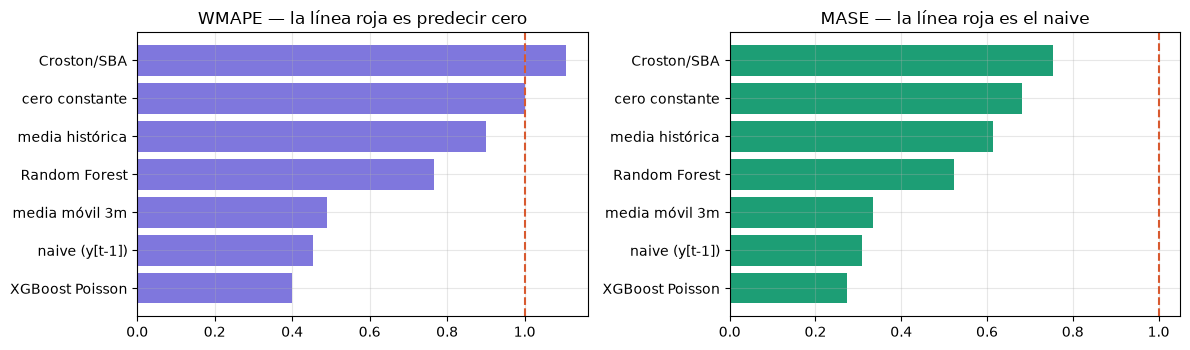

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
t = tabla.set_index("modelo")
ax[0].barh(t.index, t.WMAPE, color="#7F77DD"); ax[0].axvline(1, ls="--", color="#D85A30")
ax[0].set_title("WMAPE — la línea roja es predecir cero")
ax[1].barh(t.index, t.MASE, color="#1D9E75"); ax[1].axvline(1, ls="--", color="#D85A30")
ax[1].set_title("MASE — la línea roja es el naive")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "modelos_agregado.png", dpi=120); plt.show()

Mejor modelo: XGBoost Poisson


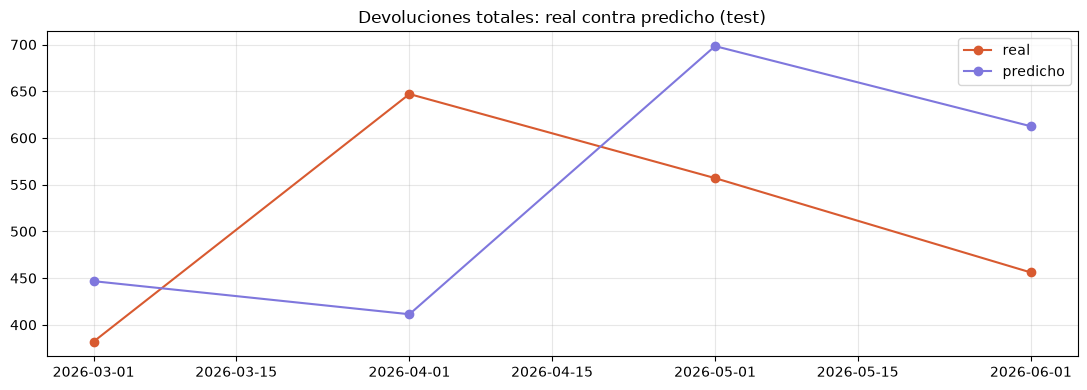

,marca,mes,devueltas,prediccion
133,SAMSUNG,2026-05-01,252.0,286.899994
132,SAMSUNG,2026-04-01,240.0,219.600006
131,SAMSUNG,2026-03-01,180.0,270.399994
28,HONOR,2026-05-01,165.0,229.300003
162,XIAOMI,2026-04-01,164.0,81.300003
11,APPLE,2026-03-01,161.0,72.400002
134,SAMSUNG,2026-06-01,149.0,213.300003
164,XIAOMI,2026-06-01,106.0,93.300003
27,HONOR,2026-04-01,102.0,34.099998
12,APPLE,2026-04-01,102.0,63.000000


In [9]:
mejor = tabla.iloc[0]["modelo"]
cmp = test[["marca", "mes", TARGET]].copy()
cmp["prediccion"] = np.round(preds[mejor], 1)
print(f"Mejor modelo: {mejor}")
piv = cmp.pivot_table(index="mes", columns="marca", values=[TARGET, "prediccion"], aggfunc="sum")
fig, ax = plt.subplots(figsize=(11, 4))
real = cmp.groupby("mes")[TARGET].sum(); pred = cmp.groupby("mes")["prediccion"].sum()
ax.plot(real.index, real.values, marker="o", label="real", color="#D85A30")
ax.plot(pred.index, pred.values, marker="o", label="predicho", color="#7F77DD")
ax.set_title("Devoluciones totales: real contra predicho (test)"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "real_vs_pred.png", dpi=120); plt.show()
cmp.sort_values(TARGET, ascending=False).head(10)

### El criterio del capstone: MAPE ≤ 15 %

El Objetivo Específico 4 fija un MAPE máximo del 15 %. Conviene calcularlo en los dos niveles y
decir con claridad cuál se cumple: a nivel de celda el MAPE divide por valores pequeños y se
dispara; a nivel del total mensual, que es donde planificación decide cuánto reponer, el
denominador es grande y la métrica es estable.

In [10]:
def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    m = y > 0
    return float(np.mean(np.abs(y[m] - yhat[m]) / y[m]) * 100)

filas = []
for k, v in preds.items():
    d = test[["marca", "mes"]].copy(); d["y"] = y_te; d["yhat"] = v
    tot = d.groupby("mes")[["y", "yhat"]].sum()
    filas.append({"modelo": k,
                  "MAPE celda %": round(mape(d.y, d.yhat), 1),
                  "MAPE total mensual %": round(mape(tot.y, tot.yhat), 1),
                  "cumple ≤15 % (mensual)": "sí" if mape(tot.y, tot.yhat) <= 15 else "no"})
pd.DataFrame(filas).sort_values("MAPE total mensual %")

,modelo,MAPE celda %,MAPE total mensual %,cumple ≤15 % (mensual)
0,naive (y[t-1]),81.2,21.2,no
2,media móvil 3m,98.5,22.9,no
6,XGBoost Poisson,45.3,28.3,no
5,Random Forest,119.0,76.4,no
1,media histórica,299.8,86.8,no
4,cero constante,100.0,100.0,no
3,Croston/SBA,261.8,111.0,no


## 7. Explicabilidad — SHAP

,variable,shap
0,desp_lag2,1.239512
1,desp_mm3,0.663239
2,desp_lag1,0.479033
3,dev_lag1,0.460591
4,marca,0.452116
5,dev_mm3,0.355053
6,desp_rezago_umbral,0.336054
7,dev_mm6,0.194026
8,mes_sin,0.180406
9,dev_lag3,0.118362


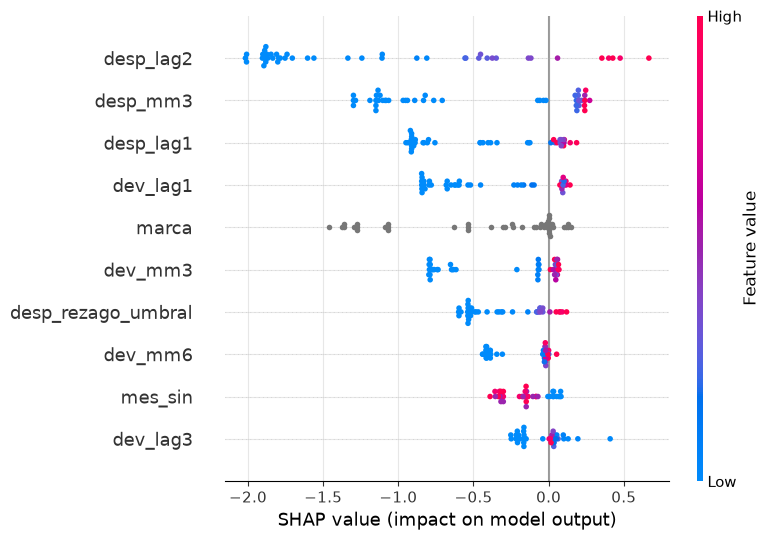

In [11]:
sys.modules.setdefault("cv2", types.ModuleType("cv2"))   # evita el aviso de numpy al importar shap
try:
    import shap
    sv = shap.TreeExplainer(xgb).shap_values(Xte)
    imp = (pd.DataFrame({"variable": Xte.columns, "shap": np.abs(sv).mean(0)})
           .sort_values("shap", ascending=False).head(12).reset_index(drop=True))
    display(imp)
    shap.summary_plot(sv, Xte, max_display=10, show=False)
    plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "shap_agregado.png", dpi=120); plt.show()
except Exception as e:
    print("shap no disponible:", e)
    display(pd.Series(xgb.feature_importances_, index=Xte.columns)
            .sort_values(ascending=False).head(12).to_frame("importancia"))

## 8. Modelo por unidad

El panel agregado tiene pocas filas porque 19 meses por 12 marcas dan 228 observaciones. A nivel de
unidad hay tres órdenes de magnitud más, y toda la información del despacho está disponible en el
momento en que ocurre: marca, precio, destino, ciudad, canal, mes.

Se entrena un clasificador y sus probabilidades se **suman por marca y mes** para obtener el mismo
volumen que predice el modelo agregado. La salida sigue siendo una estimación de volumen; cambia
cómo se calcula.

In [12]:
u = ciclo[ciclo.madura & ciclo.trazable].copy()
u = u[u.mes_despacho.isin(p.mes.unique()) | u.mes_despacho.ge(p.mes.min())]
u["mes"] = u.mes_despacho
u["precio_despacho"] = u.precio_despacho.fillna(u.precio_despacho.median())
u["mes_num"] = u.mes.dt.month

corte_u = np.sort(u.mes.unique())[-4]
utr, ute = u[u.mes < corte_u].copy(), u[u.mes >= corte_u].copy()

# Codificacion por objetivo: la tasa historica de devolucion de cada destino y
# de cada modelo. Se calcula SOLO con el tramo de entrenamiento -- hacerlo
# sobre el conjunto completo seria fuga de informacion.
GLOBAL = utr.devuelta_60d.mean()
for col, nombre in [("destino", "tasa_destino"), ("ruc", "tasa_ruc"),
                    ("sku", "tasa_sku")]:
    agg = utr.groupby(col).devuelta_60d.agg(["mean", "size"])
    # suavizado: los destinos con pocas unidades se acercan a la media global
    k = 20
    tasa = (agg["mean"] * agg["size"] + GLOBAL * k) / (agg["size"] + k)
    utr[nombre] = utr[col].map(tasa).fillna(GLOBAL)
    ute[nombre] = ute[col].map(tasa).fillna(GLOBAL)

FU = ["marca", "canal", "ciudad", "precio_despacho", "mes_sin_u", "mes_cos_u",
      "tasa_destino", "tasa_ruc", "tasa_sku"]
for df in (utr, ute):
    df["mes_sin_u"] = np.sin(2 * np.pi * df.mes_num / 12)
    df["mes_cos_u"] = np.cos(2 * np.pi * df.mes_num / 12)

print(f"train: {len(utr):,} unidades ({utr.devuelta_60d.mean():.2%} devueltas)")
print(f"test : {len(ute):,} unidades ({ute.devuelta_60d.mean():.2%} devueltas)")

train: 93,186 unidades (11.55% devueltas)
test : 5,062 unidades (16.53% devueltas)


In [13]:
Xu_tr, Xu_te = M.preparar_X(utr, FU), M.preparar_X(ute, FU)
yu_tr, yu_te = utr.devuelta_60d.astype(int), ute.devuelta_60d.astype(int)

clf = XGBClassifier(objective="binary:logistic", n_estimators=400, max_depth=5,
                    learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=(yu_tr == 0).sum() / max((yu_tr == 1).sum(), 1),
                    random_state=SEMILLA, enable_categorical=True,
                    tree_method="hist", eval_metric="auc").fit(Xu_tr, yu_tr)
prob = clf.predict_proba(Xu_te)[:, 1]
print(f"AUC en test: {roc_auc_score(yu_te, prob):.3f}   (0,5 = azar)")

AUC en test: 0.633   (0,5 = azar)


In [14]:
agg = (ute.assign(prob=prob)
          .groupby(["marca", "mes"])
          .agg(real=("devuelta_60d", "sum"), predicho=("prob", "sum"))
          .reset_index())
comparativa = pd.DataFrame([
    M.evaluar("agregado (XGBoost mensual)", y_te, preds["XGBoost Poisson"], y_tr),
    M.evaluar("bottom-up (por unidad)", agg.real.to_numpy(), agg.predicho.to_numpy(), y_tr),
]).drop(columns=["MAPE_agg_%"], errors="ignore")
comparativa

,modelo,WMAPE,MAE,RMSE,MASE,sesgo,pct_subestim
0,agregado (XGBoost mensual),0.4006,18.591,33.852,0.273,2.892,47.8
1,bottom-up (por unidad),0.9617,50.309,106.200,0.739,40.830,53.3


### Qué está haciendo el modelo por unidad — matriz de confusión

El modelo agregado predice un número, así que no tiene matriz de confusión. El modelo por unidad sí:
decide, para cada equipo despachado, si se quedará parado o no. Verlo en forma de matriz es la
manera más directa de entender qué acierta y qué falla.

In [15]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_curve

yb = yu_te.values
for corte_p in (0.5, 0.6, 0.7):
    pred = (prob >= corte_p).astype(int)
    cm = confusion_matrix(yb, pred)
    pr_, rc_, f1_, _ = precision_recall_fscore_support(yb, pred, average="binary",
                                                       zero_division=0)
    print(f"--- umbral de decisión {corte_p} ---")
    print(pd.DataFrame(cm, index=["real: se quedó", "real: NO se quedó"][::-1],
                       columns=["predice: no", "predice: sí"]).to_string())
    print(f"    precisión {pr_:.3f} | cobertura {rc_:.3f} | F1 {f1_:.3f}")
    print("")

--- umbral de decisión 0.5 ---
                   predice: no  predice: sí
real: NO se quedó         3348          877
real: se quedó             477          360
    precisión 0.291 | cobertura 0.430 | F1 0.347

--- umbral de decisión 0.6 ---
                   predice: no  predice: sí
real: NO se quedó         3726          499
real: se quedó             597          240
    precisión 0.325 | cobertura 0.287 | F1 0.305

--- umbral de decisión 0.7 ---
                   predice: no  predice: sí
real: NO se quedó         3953          272
real: se quedó             725          112
    precisión 0.292 | cobertura 0.134 | F1 0.183



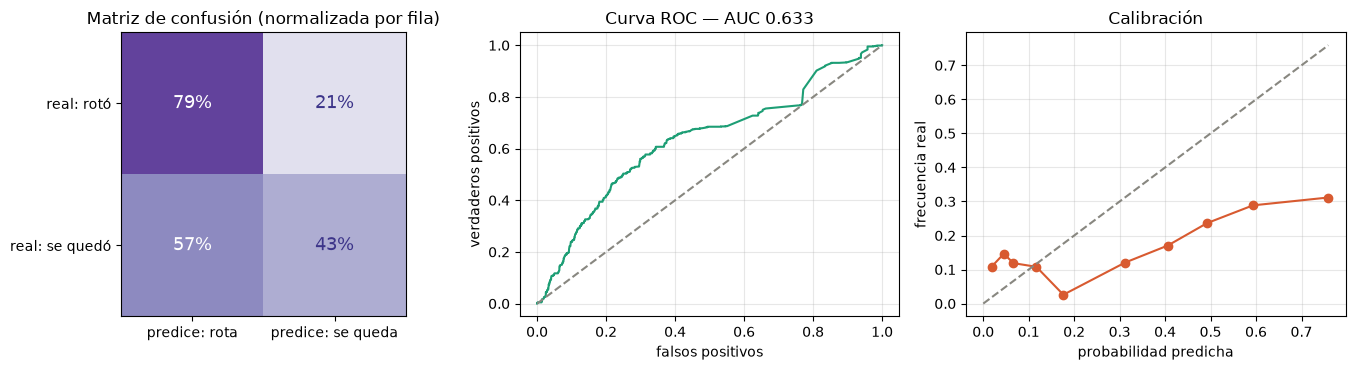

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

cm = confusion_matrix(yb, (prob >= 0.5).astype(int), normalize="true")
im = ax[0].imshow(cm, cmap="Purples", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i,j]:.0%}", ha="center", va="center",
                   color="white" if cm[i, j] > .5 else "#3C3489", fontsize=13)
ax[0].set_xticks([0, 1], ["predice: rota", "predice: se queda"])
ax[0].set_yticks([0, 1], ["real: rotó", "real: se quedó"])
ax[0].set_title("Matriz de confusión (normalizada por fila)"); ax[0].grid(False)

fpr, tpr, _ = roc_curve(yb, prob)
ax[1].plot(fpr, tpr, color="#1D9E75"); ax[1].plot([0, 1], [0, 1], ls="--", color="#888780")
ax[1].set_xlabel("falsos positivos"); ax[1].set_ylabel("verdaderos positivos")
ax[1].set_title(f"Curva ROC — AUC {roc_auc_score(yb, prob):.3f}")

bins = pd.qcut(prob, 10, duplicates="drop")
cal = pd.DataFrame({"p": prob, "y": yb}).groupby(bins, observed=True).agg(
    predicho=("p", "mean"), real=("y", "mean"))
ax[2].plot(cal.predicho, cal.real, marker="o", color="#D85A30")
ax[2].plot([0, cal.max().max()], [0, cal.max().max()], ls="--", color="#888780")
ax[2].set_xlabel("probabilidad predicha"); ax[2].set_ylabel("frecuencia real")
ax[2].set_title("Calibración")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "diagnostico_unidad.png", dpi=120)
plt.show()

**Cómo leer estos tres gráficos.**

La **matriz** dice qué hace el modelo cuando tiene que decidir. La **ROC** mide si sabe ordenar:
puesto a elegir entre una unidad que se quedó y una que rotó, con qué frecuencia le da más
probabilidad a la correcta. La **calibración** comprueba si sus probabilidades significan algo: si
dice 30 %, ¿se quedan efectivamente 3 de cada 10?

La calibración es la que importa para el uso real, porque la salida que se suma para obtener el
volumen mensual son esas probabilidades, no las decisiones binarias.

### Diagnóstico del modelo agregado

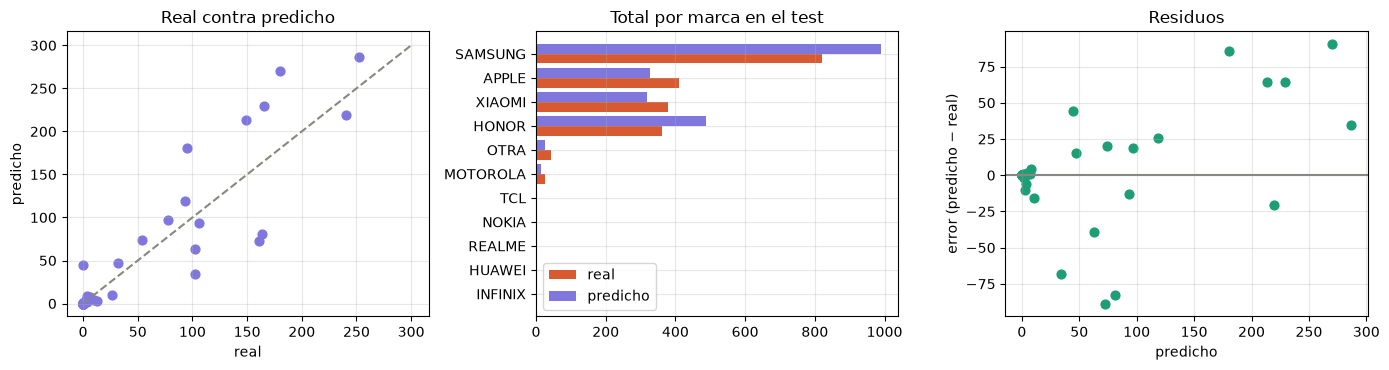

Error por marca (suma sobre los 4 meses de prueba):
           real        pred  error  error_pct
marca                                        
INFINIX     0.0    0.081659    0.0        NaN
HUAWEI      0.0    0.090235    0.0        NaN
REALME      0.0    0.223763    0.0        NaN
NOKIA       0.0    0.086329    0.0        NaN
TCL         0.0    1.025215    1.0        NaN
MOTOROLA   26.0   14.758763  -11.0      -43.2
OTRA       43.0   27.037197  -16.0      -37.1
HONOR     362.0  488.347717  126.0       34.9
XIAOMI    380.0  319.130981  -61.0      -16.0
APPLE     410.0  328.253387  -82.0      -19.9
SAMSUNG   821.0  990.206787  169.0       20.6


In [17]:
diag = test[["marca", "mes", TARGET]].copy()
diag["pred"] = preds[mejor]
diag["error"] = diag.pred - diag[TARGET]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(diag[TARGET], diag.pred, s=40, color="#7F77DD")
lim = max(diag[TARGET].max(), diag.pred.max()) * 1.05
ax[0].plot([0, lim], [0, lim], ls="--", color="#888780")
ax[0].set_xlabel("real"); ax[0].set_ylabel("predicho"); ax[0].set_title("Real contra predicho")

pm_ = diag.groupby("marca").agg(real=(TARGET, "sum"), pred=("pred", "sum"))
pm_ = pm_[pm_.real + pm_.pred > 0].sort_values("real")
y_ = np.arange(len(pm_))
ax[1].barh(y_ - .2, pm_.real, height=.4, color="#D85A30", label="real")
ax[1].barh(y_ + .2, pm_.pred, height=.4, color="#7F77DD", label="predicho")
ax[1].set_yticks(y_, pm_.index); ax[1].legend(); ax[1].set_title("Total por marca en el test")

ax[2].axhline(0, color="#888780")
ax[2].scatter(diag.pred, diag.error, s=40, color="#1D9E75")
ax[2].set_xlabel("predicho"); ax[2].set_ylabel("error (predicho − real)")
ax[2].set_title("Residuos")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "diagnostico_agregado.png", dpi=120)
plt.show()

print("Error por marca (suma sobre los 4 meses de prueba):")
print(pm_.assign(error=lambda x: (x.pred - x.real).round(0),
                 error_pct=lambda x: ((x.pred - x.real) / x.real.replace(0, np.nan) * 100).round(1))
        .to_string())

## 9. Ajuste de la demanda neta — Objetivo Específico 5

$$\text{demanda\_neta}[m, t+1] = \text{despachos proyectados}[m, t+1] - \hat{y}[m, t+1]$$

In [18]:
salida = test[["marca", "mes", "despachadas", TARGET]].copy()
salida["dev_predicha"] = np.round(preds[mejor], 1)
salida["demanda_neta"] = (salida.despachadas - salida.dev_predicha).clip(lower=0)
salida["ajuste_pct"] = (salida.dev_predicha / salida.despachadas.replace(0, np.nan) * 100).round(2)

print(f"Demanda bruta      : {salida.despachadas.sum():>10,.0f} unidades")
print(f"Devolución predicha: {salida.dev_predicha.sum():>10,.0f} unidades")
print(f"Devolución real    : {salida[TARGET].sum():>10,.0f} unidades")
print(f"Demanda neta       : {salida.demanda_neta.sum():>10,.0f} unidades")
print("")
print(f"Ajuste medio sobre la demanda: "
      f"{salida.dev_predicha.sum()/salida.despachadas.sum():.2%}")
salida.sort_values("dev_predicha", ascending=False).head(10)

Demanda bruta      :     24,113 unidades
Devolución predicha:      2,169 unidades
Devolución real    :      2,042 unidades
Demanda neta       :     21,945 unidades

Ajuste medio sobre la demanda: 8.99%


,marca,mes,despachadas,devueltas,dev_predicha,demanda_neta,ajuste_pct
133,SAMSUNG,2026-05-01,2156.0,252.0,286.899994,1869.100006,13.31
131,SAMSUNG,2026-03-01,3901.0,180.0,270.399994,3630.600006,6.93
28,HONOR,2026-05-01,2100.0,165.0,229.300003,1870.699997,10.92
132,SAMSUNG,2026-04-01,2822.0,240.0,219.600006,2602.399994,7.78
134,SAMSUNG,2026-06-01,2266.0,149.0,213.300003,2052.699997,9.41
29,HONOR,2026-06-01,303.0,95.0,180.600006,122.399994,59.60
14,APPLE,2026-06-01,807.0,93.0,118.599998,688.400002,14.70
163,XIAOMI,2026-05-01,543.0,78.0,97.099998,445.900002,17.88
164,XIAOMI,2026-06-01,1135.0,106.0,93.300003,1041.699997,8.22
162,XIAOMI,2026-04-01,930.0,164.0,81.300003,848.699997,8.74


In [19]:
salida.to_parquet(PROC / "v2_predicciones.parquet", index=False)
tabla.to_csv(REPORTES / "metricas_modelo_agregado.csv", index=False)
comparativa.to_csv(REPORTES / "metricas_comparativa.csv", index=False)
print("Guardado en reports/ y data/processed/")

Guardado en reports/ y data/processed/


---

## 10. Conclusión

**Qué se logró.** Un pipeline completo que parte de 1.015 archivos de Excel y llega a una
predicción de volumen de devolución por marca y mes, con la variable objetivo construida desde
cero a partir del cruce entre despachos y snapshots de inventario.

**Los tres hallazgos de mayor valor** no vienen del modelo sino de la construcción del target:

1. **El umbral de días se puede validar con datos.** Contrastando la regla contra el retorno físico
   observado, el punto de mejor equilibrio está alrededor de los 75 días. El umbral de 60 que
   propuso el negocio queda dentro de la meseta y es defendible, pero ahora con evidencia detrás.
2. **El reporte de ventas de 2024 está incompleto** —solo cinco meses—, lo que obligó a acotar la
   ventana de trabajo a partir de enero de 2025. Sin ese control, todo 2024 habría entrado al
   modelo con el target inflado.
3. **El 8 % de las unidades despachadas no es rastreable** en los snapshots, y excluirlas cambia
   por completo el perfil de riesgo por distribuidor.

**Limitaciones que hay que declarar en el informe.**

- La ventana útil es de 19 meses, de modo que cada mes calendario se observa una o dos veces: no
  alcanza para validar estacionalidad anual con robustez.
- Noviembre de 2025 tiene solo 4 días de snapshot.
- Las SIM quedan fuera del alcance: su reporte de inventario trae el nombre de la bodega y no el
  código, así que no cruza con el catálogo.

**Trabajo futuro inmediato.** Pedir al cliente el reporte de ventas completo de 2024 y el catálogo
de bodegas con el canal zonificado. Lo primero extendería la ventana de 19 a 33 meses y permitiría
validar la estacionalidad; lo segundo ampliaría la cobertura de distribuidores.